# Part B — Understanding the images

## B.1 Six sample images

Three images the inspector marked as **OK**, and three marked as **defective** — one of each defect type that appears in `train.csv` (`edge_chip`, `stain`, `scratch`).


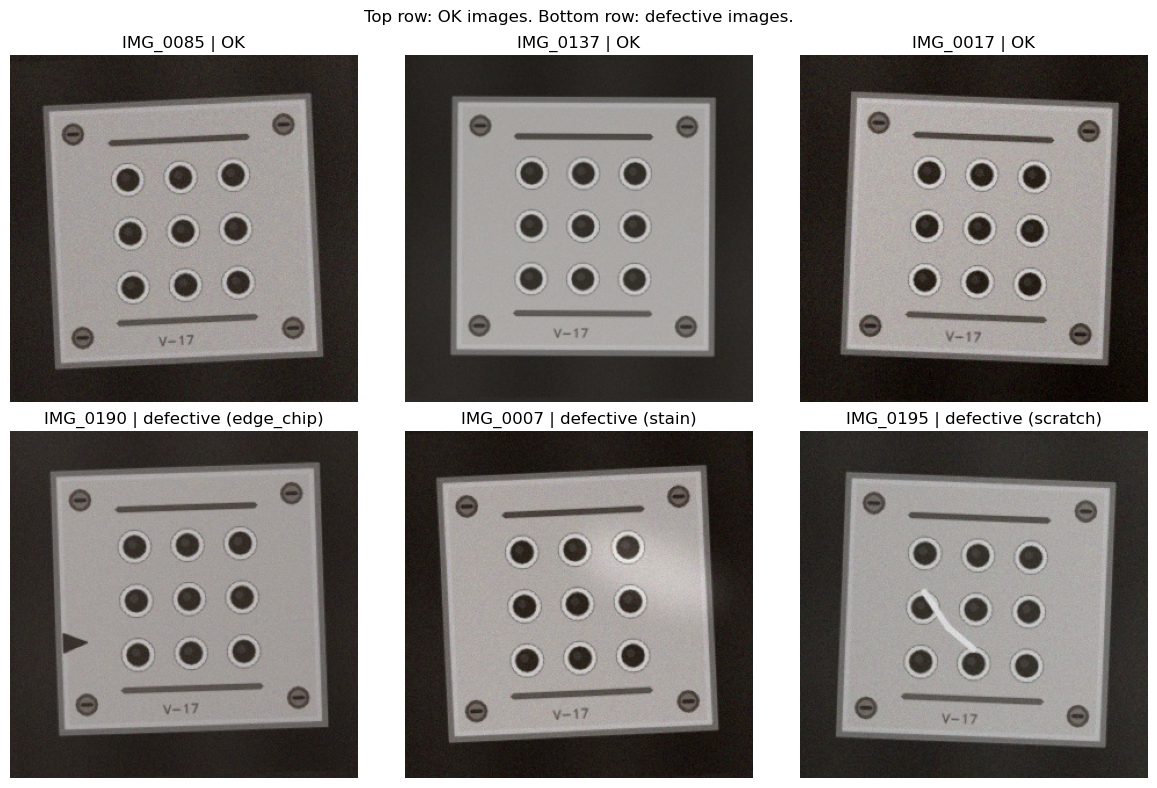

In [114]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path(".")
SEED = 42  # constant seed, so the same images are chosen every run
train = pd.read_csv(DATA_DIR / "train.csv")

# 3 OK images, and one defective image of each defect type
good = train[train["inspector_label"] == 0].sample(3, random_state=SEED)
bad = (train.set_index("image_id")
       .loc[["IMG_0190", "IMG_0007", "IMG_0195"]]  # edge_chip, stain, scratch
       .reset_index())
samples = pd.concat([good, bad])

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    ax.imshow(Image.open(DATA_DIR / row["file"]))
    status = "OK" if row["inspector_label"] == 0 else f"defective ({row['inspector_type']})"
    ax.set_title(f"{row['image_id']} | {status}")
    ax.axis("off")
fig.suptitle("Top row: OK images. Bottom row: defective images.")
plt.tight_layout()
plt.show()

### Main visual difference between normal and defective images

In normal images (inspector_label = 0), the component's surface is smooth and uniform, its outer edges are intact and symmetrical, and all mounting holes are clear and present, even when the component is rotated or when the overall image quality is poor (too dark, too bright, or blurry).
In contrast, defective images (inspector_label = 1) show a clear local change in texture or shape: a break in surface uniformity (a dark spot in stain or a sharp line in scratch), a damaged outer border (edge_chip), or a missing structural part (missing_hole).
Additionally, looking at the images by eye, we can see both False Positives and False Negatives in the data, meaning some normal components were labeled as defective, and some defective ones were labeled as normal.





## B.2 A function with two numeric features

Both features start from the same step: the image is read in greyscale and **normalised** to a fixed mean and standard deviation, so a dark photo and a bright photo of the same component look alike.

**1. `local_anomaly_score`** - local surface anomaly (top-hat + black-hat morphology).
Instead of looking at global brightness, I subtract the *local background*. A morphological top-hat keeps what is **brighter** than its close surroundings, and a black-hat keeps what is **darker**. A normal surface, even if it is dark or lit at an angle, changes smoothly, so both residuals stay near 0. A stain or a scratch is a sharp local jump relative to its neighbours, so it stands out. The score is the strongest residual divided by the image's typical residual level.

**2. `contour_complexity`** - geometric irregularity (perimeter relative to area).
Canny finds the boundary lines of the component, and the score is their total length divided by the square root of the component's area (from an Otsu mask). The measure does not care about rotation or weak lighting. An `edge_chip` makes the border jagged and longer, and a `missing_hole` removes a whole inner circle of edges - both change the ratio compared with a normal, symmetric component.


In [115]:
import math
import cv2
import numpy as np

KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))  # wider than a scratch
MARGIN = 10                                                     # skip the image border


def image_features(path):
    """Read one image and return two numeric features."""
    grey = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE).astype(np.float32)
    grey = (grey - grey.mean()) / (grey.std() + 1e-6) * 40 + 128   # normalise exposure

    # 1) local_anomaly_score: what is brighter (top-hat) or darker (black-hat)
    #    than its local background, smoothed so one noisy pixel cannot win
    tophat = cv2.morphologyEx(grey, cv2.MORPH_TOPHAT, KERNEL)
    blackhat = cv2.morphologyEx(grey, cv2.MORPH_BLACKHAT, KERNEL)
    residual = cv2.blur(np.maximum(tophat, blackhat), (3, 3))[MARGIN:-MARGIN, MARGIN:-MARGIN]
    local_anomaly_score = residual.max() / (residual.std() + 1e-6)

    # 2) contour_complexity: total length of the boundary lines / sqrt(component area)
    grey_u8 = np.clip(grey, 0, 255).astype(np.uint8)
    edges = cv2.Canny(cv2.GaussianBlur(grey_u8, (3, 3), 0), 50, 150)
    contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
    perimeter = sum(cv2.arcLength(c, False) for c in contours)
    _, mask = cv2.threshold(grey_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    area = max(cv2.countNonZero(mask), 1)
    contour_complexity = perimeter / math.sqrt(area)

    return {"local_anomaly_score": float(local_anomaly_score),
            "contour_complexity": float(contour_complexity)}


# check on the six images from B.1
check = pd.DataFrame([image_features(DATA_DIR / f) for f in samples["file"]],
                     index=samples["image_id"]).round(2)
check["label"] = samples["inspector_label"].values
check["type"] = samples["inspector_type"].values
check


,local_anomaly_score,contour_complexity,label,type
image_id,,,,
IMG_0085,7.72,30.49,0,none
IMG_0137,6.73,20.99,0,none
IMG_0017,7.68,29.49,0,none
IMG_0190,8.46,29.83,1,edge_chip
IMG_0007,7.35,29.53,1,stain
IMG_0195,8.57,31.78,1,scratch


## B.3 The features for all training images, and one comparison

I compute both features for the 168 training images and compare `local_anomaly_score` between the OK group and the defective group.


In [116]:
feats = pd.DataFrame([image_features(DATA_DIR / f) for f in train["file"]])
df = pd.concat([train, feats], axis=1)
print("rows:", len(df), "| missing values:", int(feats.isna().sum().sum()))

df.groupby("inspector_label")["local_anomaly_score"].agg(
    n="count", mean="mean", median="median", std="std",
    p90=lambda s: s.quantile(0.9)).round(2).rename(index={0: "0 - OK", 1: "1 - defective"})


rows: 168 | missing values: 0


,n,mean,median,std,p90
inspector_label,,,,,
0 - OK,112,7.14,7.08,0.52,7.94
1 - defective,56,7.73,7.52,1.16,9.26


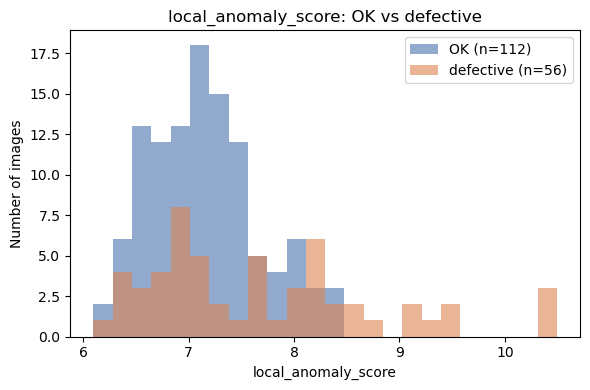

median by defect type:
inspector_type
edge_chip       7.53
missing_hole    6.69
none            7.08
scratch         9.19
stain           7.41


In [117]:
fig, ax = plt.subplots(figsize=(6, 4))
ok = df.loc[df["inspector_label"] == 0, "local_anomaly_score"]
bad = df.loc[df["inspector_label"] == 1, "local_anomaly_score"]
bins = np.linspace(df["local_anomaly_score"].min(), df["local_anomaly_score"].quantile(0.99), 25)
ax.hist(ok.clip(upper=bins[-1]), bins=bins, alpha=0.6, label=f"OK (n={len(ok)})", color="#4C72B0")
ax.hist(bad.clip(upper=bins[-1]), bins=bins, alpha=0.6, label=f"defective (n={len(bad)})", color="#DD8452")
ax.set_xlabel("local_anomaly_score")
ax.set_ylabel("Number of images")
ax.set_title("local_anomaly_score: OK vs defective")
ax.legend()
plt.tight_layout()
plt.show()

print("median by defect type:")
print(df.groupby("inspector_type")["local_anomaly_score"].median().round(2).to_string())


### Finding

- The OK images are packed tightly: median **7.08**, standard deviation 0.52, and none of them goes above 9.
- The defective images have a slightly higher centre (median 7.52) but, more importantly, a **long upper tail** (standard deviation 1.16, p90 9.26). **14.3%** of the defective images score above 9, against **0%** of the OK images - so a high score is a reliable signal, while a normal score says little.
- By defect type the score works as the theory says for **scratches** (median 9.19, the clear leader): a thin line is exactly the sharp local jump that top-hat / black-hat picks up. A `stain` (7.41) and an `edge_chip` (7.53) sit only a little above OK (7.08), and a `missing_hole` (6.69) is even lower - a hole that is *missing* is an absence of structure, not a bright or dark spot.
- Overall separation (AUC) is **0.64** for `local_anomaly_score` and **0.66** for `contour_complexity`. Neither is enough alone, but they react to different defect types, so combining them is more useful than either one.
